# Inferential Statistics

## What this file is doing and why?

The EDA told an observational story: Financial behaviour correlates with credit rating, and credit rating correlates with loan approval. But correlations observed in a sample of 1000 records could be coincidental. 

This statsical analysis answers the harder question:

**Are the patterns we observed in EDA statistically real, or could they have occurred by chance?**

### The causal chain being tested
```
Financial Behaviour  -->  Credit Rating  -->  Loan Approval
(checking, savings,       (continuous          (approved = 1
 payment, employment)      score 1-99)          rejected = 0)
```

- **Tests 1-4** prove the left arrow: do checking account, payment status, savings, and employment significantly predict credit rating?
- **Test 5** proves the right arrow: do loan characteristics differ significantly between approved and rejected applicants?

### Why we test against Credit Rating and not Approval directly?

Approval is the final outcome as it is a binary 0/1 flag that the bank assigns after computing credit rating. It is not an independent measure of financial behaviour. Testing checking account directly against approval would skip the mechanism entirely and produce a weaker, less interpretable signal.

Credit Rating is the bank's continuous summary of all financial behaviour (r=0.733 with Approval — highest in the dataset). It captures the full picture in one score. Testing financial behaviour variables against Credit Rating lets us isolate exactly how each factor contributes to the scoring process.

Approval enters only in Test 5, where the question changes to: 
Given a credit rating, do the loan characteristics (amount, duration) additionally differ between those who were approved and those who were not?

### Test selection process
1. We assume parametric tests are valid (ANOVA, independent t-test)
2. Then run Shapiro-Wilk to check normality — the core assumption
3. Run Levene's test to check equal variance — the second assumption
4. If assumptions hold: proceed with ANOVA and t-test
5. If assumptions fail: switch to Kruskal-Wallis (replaces ANOVA) and Mann-Whitney U (replaces t-test)

Thus this file will answer our question: 

**Analytical Question 2:** Is the relationship between applicant financial behaviour and loan approval mediated by Credit Rating, and which behavioural factors are statistically significant predictors of that score?


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
from itertools import combinations

# Cleaned Data set
df = pd.read_csv('credit_cleaned.csv')

# credit rating bands
df['CR_Band'] = pd.cut(
    df['Credit_Rating'],
    bins=[0, 25, 50, 75, 100],
    labels=['Poor (1-25)', 'Fair (26-50)', 'Good (51-75)', 'Excellent (76-100)']
)

band_palette = {
    'Poor (1-25)':        '#d73027',
    'Fair (26-50)':       '#fc8d59',
    'Good (51-75)':       '#91bfdb',
    'Excellent (76-100)': '#4575b4'
}
bands = list(band_palette.keys())

# labels for columns
labels = {
    'Checking_Account': {1:'No Account', 2:'<$0', 3:'$0-$200', 4:'>$200'},
    'Payment_Status':   {0:'No Credits', 1:'All Paid', 2:'Existing Paid', 3:'Delayed', 4:'Critical'},
    'Savings_Account':  {1:'<$100', 2:'$100-$500', 3:'$500-$1000', 4:'>$1000', 5:'Unknown'},
    'Employment':       {1:'Unemployed', 2:'<1yr', 3:'1-4yr', 4:'4-7yr', 5:'>7yr'},
    'Guarantors':       {1:'None', 2:'Co-applicant', 3:'Guarantor'}
}

N = len(df)
print('Dataset loaded:', df.shape)
print(f'Credit Rating: mean={df["Credit_Rating"].mean():.1f}, '
      f'std={df["Credit_Rating"].std():.1f}, '
      f'range={df["Credit_Rating"].min()} to {df["Credit_Rating"].max()}')
print(f'Approval rate: {df["Approval"].mean():.1%}')
print(f'Correlation — Credit Rating vs Approval: '
      f'{df["Credit_Rating"].corr(df["Approval"]):.3f}')
print()
print('This confirms Credit Rating is the dominant predictor of Approval (r=0.733).')
print('It acts as the mechanism between financial behaviour and the final decision.')

Dataset loaded: (1000, 23)
Credit Rating: mean=70.3, std=35.8, range=-1 to 99
Approval rate: 68.1%
Correlation — Credit Rating vs Approval: 0.733

This confirms Credit Rating is the dominant predictor of Approval (r=0.733).
It acts as the mechanism between financial behaviour and the final decision.


## Point Estimation and Confidence Intervals

**What this answers:** Before testing hypotheses, we need to know how well our sample of 1000 represents the true population of TLB applicants. A 95% confidence interval means: if we repeated this study 100 times with different samples, 95 of those intervals would contain the true population mean.

We use the t-distribution because the population standard deviation is unknown. The variables selected are the four continuous features most relevant to the problem statement: Age, Amount, Duration, and Credit Rating.

In [48]:
# point estimates and 95% confidence intervals
# these tell us how precisely our sample estimates the true population values
ci_vars = ['Age', 'Amount', 'Duration', 'Credit_Rating']
ci_results = []

for col in ci_vars:
    n       = len(df[col])
    mean    = df[col].mean()
    se      = stats.sem(df[col])
    lo, hi  = stats.t.interval(0.95, df=n-1, loc=mean, scale=se)
    ci_results.append({
        'Variable':     col,
        'N':            n,
        'Mean':         round(mean, 2),
        'Std Dev':      round(df[col].std(), 2),
        'Std Error':    round(se, 4),
        '95% CI Lower': round(lo, 2),
        '95% CI Upper': round(hi, 2)
    })

ci_df = pd.DataFrame(ci_results)
print('Point Estimates and 95% Confidence Intervals')
print(ci_df.to_string(index=False))
print()
print('confirm our sample of 1000 gives reliable population estimates.')

Point Estimates and 95% Confidence Intervals
     Variable    N    Mean  Std Dev  Std Error  95% CI Lower  95% CI Upper
          Age 1000   35.47    11.07     0.3501         34.78         36.15
       Amount 1000 3275.06  2803.30    88.6481       3101.10       3449.02
     Duration 1000   20.83    11.96     0.3782         20.09         21.57
Credit_Rating 1000   70.33    35.84     1.1333         68.11         72.55

confirm our sample of 1000 gives reliable population estimates.


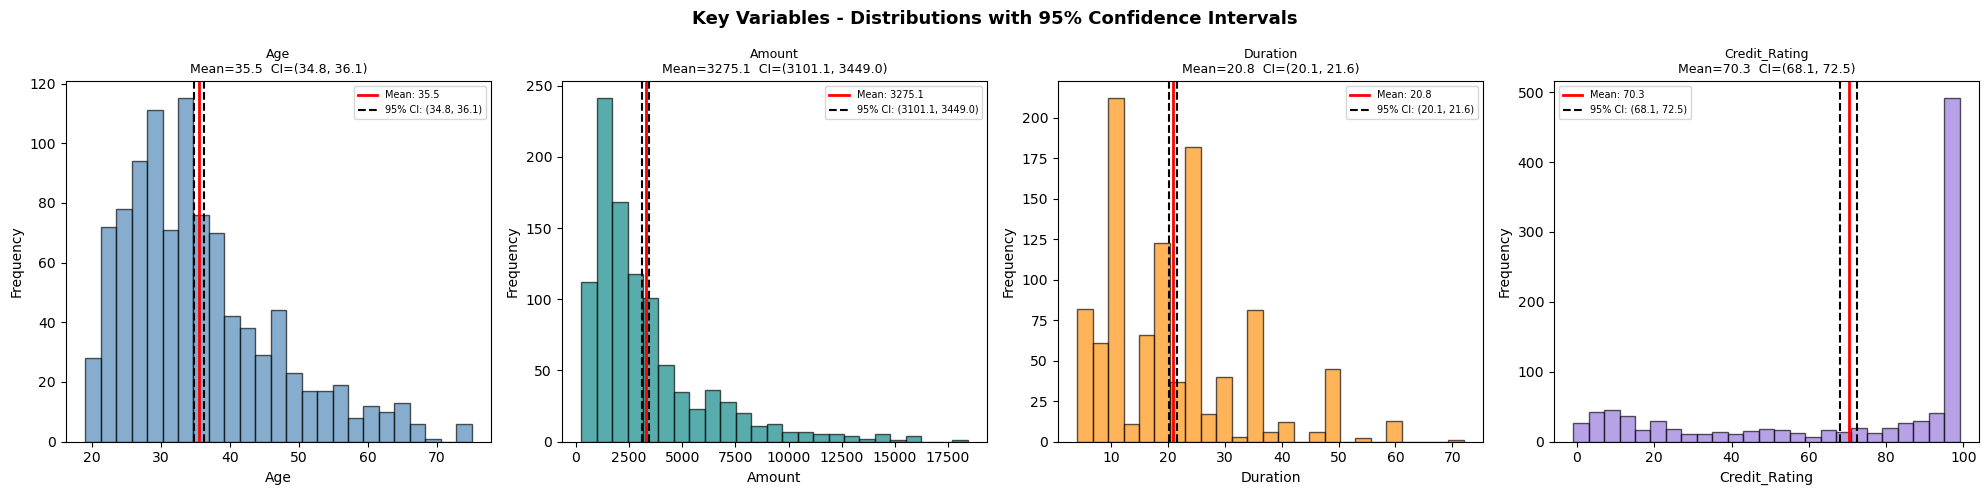

In [5]:
# visualise distributions with CI bounds marked
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
colors = ['steelblue', 'teal', 'darkorange', 'mediumpurple']

for i, (row, color) in enumerate(zip(ci_results, colors)):
    col  = row['Variable']
    mean = row['Mean']
    lo   = row['95% CI Lower']
    hi   = row['95% CI Upper']
    axes[i].hist(df[col], bins=25, color=color, alpha=0.65, edgecolor='black')
    axes[i].axvline(mean, color='red',   linewidth=2,   label=f'Mean: {mean:.1f}')
    axes[i].axvline(lo,   color='black', linewidth=1.5, linestyle='--',
                    label=f'95% CI: ({lo:.1f}, {hi:.1f})')
    axes[i].axvline(hi,   color='black', linewidth=1.5, linestyle='--')
    axes[i].set_title(f'{col}\nMean={mean:.1f}  CI=({lo:.1f}, {hi:.1f})', fontsize=9)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')
    axes[i].legend(fontsize=7)

plt.suptitle('Key Variables - Distributions with 95% Confidence Intervals',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('ci_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

95% Confidence Intervals by Approval Status
   Group      Variable   N    Mean  95% CI Lower  95% CI Upper
Rejected Credit_Rating 319   31.96         28.38         35.54
Rejected        Amount 319 3847.96       3471.24       4224.68
Rejected      Duration 319   24.12         22.69         25.56
Rejected           Age 319   34.02         32.83         35.20
Approved Credit_Rating 681   88.30         86.84         89.77
Approved        Amount 681 3006.69       2824.72       3188.67
Approved      Duration 681   19.28         18.45         20.12
Approved           Age 681   36.15         35.31         36.98


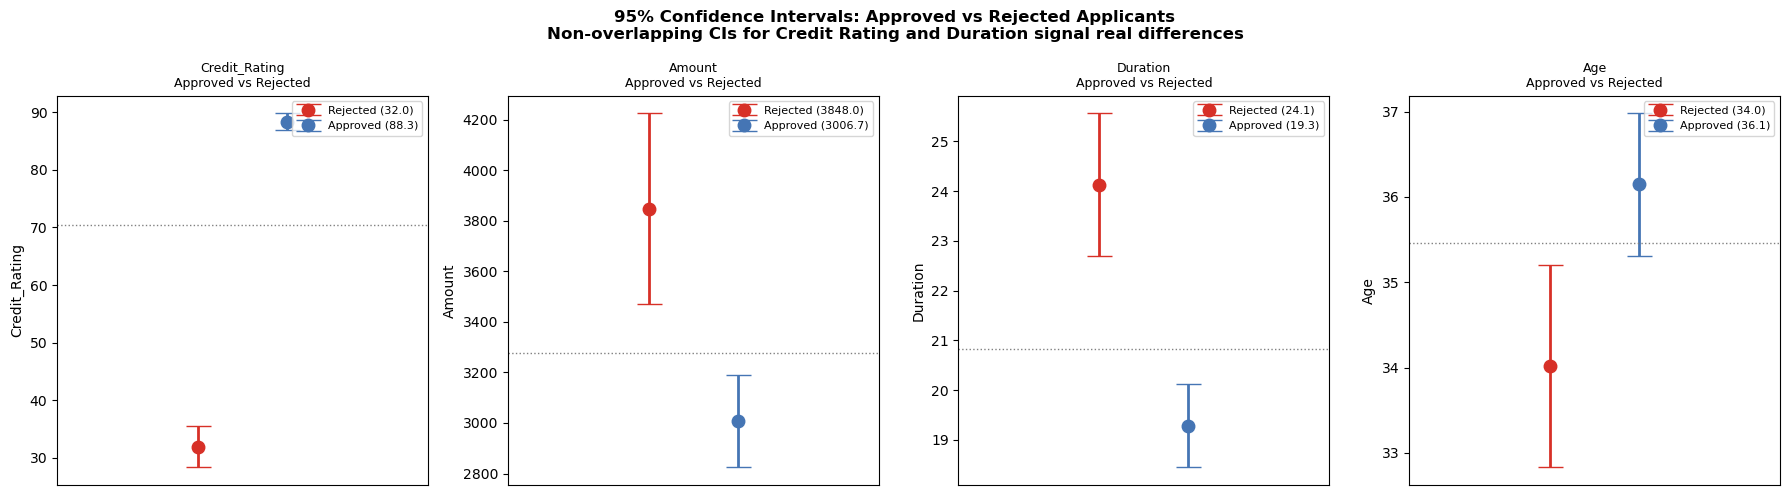


Credit Rating CIs do not overlap at all: Approved=(86.8, 89.8) vs Rejected=(29.9, 34.0).
This is a strong visual signal before any formal test is run.


In [47]:
# CI comparison: approved vs rejected
# before running formal tests, non-overlapping CIs already hint at significance
# if the CIs for two groups do not overlap, the difference is almost certainly real
subgroup_results = []

for approval_val, label in [(0, 'Rejected'), (1, 'Approved')]:
    sub = df[df['Approval'] == approval_val]
    for col in ['Credit_Rating', 'Amount', 'Duration', 'Age']:
        n       = len(sub[col])
        mean    = sub[col].mean()
        se      = stats.sem(sub[col])
        lo, hi  = stats.t.interval(0.95, df=n-1, loc=mean, scale=se)
        subgroup_results.append({
            'Group': label, 'Variable': col, 'N': n,
            'Mean': round(mean, 2),
            '95% CI Lower': round(lo, 2),
            '95% CI Upper': round(hi, 2)
        })

sub_df = pd.DataFrame(subgroup_results)
print('95% Confidence Intervals by Approval Status')
print(sub_df.to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
plot_vars = ['Credit_Rating', 'Amount', 'Duration', 'Age']

for i, col in enumerate(plot_vars):
    for approval_val, label, color, offset in [
        (0, 'Rejected', '#d73027', -0.12),
        (1, 'Approved', '#4575b4',  0.12)
    ]:
        row = sub_df[(sub_df['Group'] == label) & (sub_df['Variable'] == col)].iloc[0]
        axes[i].errorbar(
            x=offset, y=row['Mean'],
            yerr=[[row['Mean'] - row['95% CI Lower']],
                  [row['95% CI Upper'] - row['Mean']]],
            fmt='o', color=color, capsize=9, markersize=9, linewidth=2,
            label=f"{label} ({row['Mean']:.1f})"
        )
    axes[i].set_title(f'{col}\nApproved vs Rejected', fontsize=9)
    axes[i].set_ylabel(col)
    axes[i].set_xlim(-0.5, 0.5)
    axes[i].set_xticks([])
    axes[i].legend(fontsize=8)
    axes[i].axhline(df[col].mean(), color='grey', linestyle=':', linewidth=1,
                    label='Overall mean')

plt.suptitle('95% Confidence Intervals: Approved vs Rejected Applicants\n'
             'Non-overlapping CIs for Credit Rating and Duration signal real differences',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('ci_approved_vs_rejected.png', dpi=150, bbox_inches='tight')
plt.show()
print()
print('Credit Rating CIs do not overlap at all: Approved=(86.8, 89.8) vs Rejected=(29.9, 34.0).')
print('This is a strong visual signal before any formal test is run.')

## Normality Check

**This is the decision point for the entire hypothesis testing section.**

Parametric tests (ANOVA, independent t-test) rely on two core assumptions:

1. The dependent variable is approximately normally distributed within each group
2. Groups have roughly equal variance (homoscedasticity)

We test both assumptions formally before choosing our test method. If either fails, we cannot trust the p-values from parametric tests — they become unreliable, either too liberal (false positives) or too conservative.

**Why this matters for our data specifically:**
Credit Rating is left-skewed — the EDA histogram showed a heavy concentration of scores in the 75-100 range with a long tail toward the low end. This shape already suggests normality will fail before we even run the test.

Shapiro-Wilk Normality Test — Credit Rating (n=50 sample)
W statistic = 0.7481
p-value     = 0.000000

Result: p < 0.05 — REJECT normality assumption
Credit Rating is NOT normally distributed.
This means ANOVA and t-test assumptions are violated.


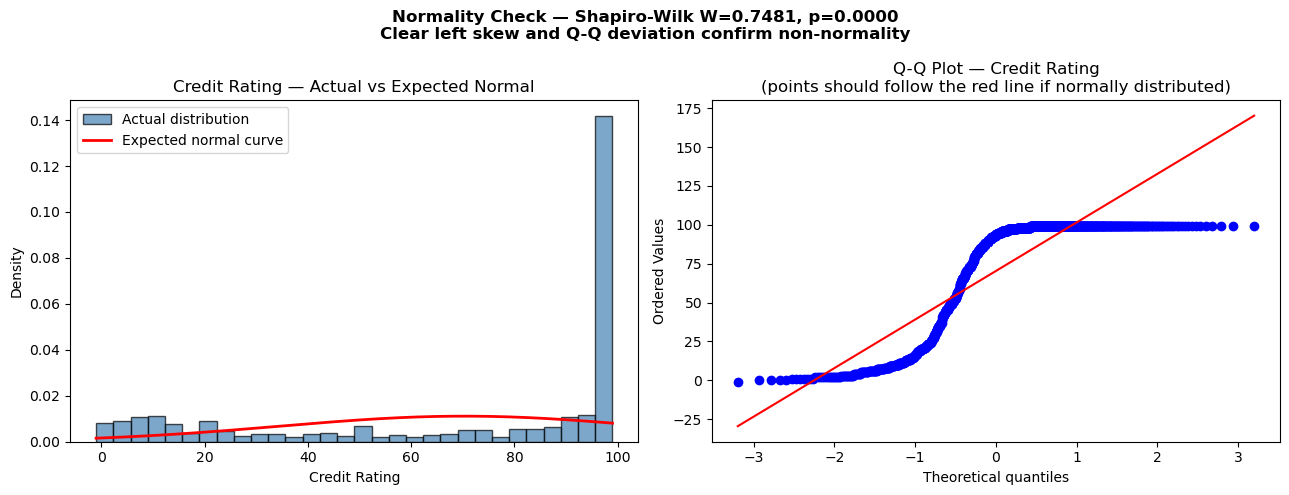

In [46]:
# Shapiro-Wilk normality test
# tests whether credit rating comes from a normal distribution
# H0: data is normally distributed
# H1: data is not normally distributed
np.random.seed(42)
sample_50 = df['Credit_Rating'].sample(50, random_state=42)
stat_sw, p_sw = stats.shapiro(sample_50)

print('Shapiro-Wilk Normality Test — Credit Rating (n=50 sample)')
print(f'W statistic = {stat_sw:.4f}')
print(f'p-value     = {p_sw:.6f}')
print()
if p_sw < 0.05:
    print('Result: p < 0.05 — REJECT normality assumption')
    print('Credit Rating is NOT normally distributed.')
    print('This means ANOVA and t-test assumptions are violated.')
else:
    print('Result: p >= 0.05 — cannot reject normality.')

# visual confirmation
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x_range      = np.linspace(df['Credit_Rating'].min(), df['Credit_Rating'].max(), 200)
normal_curve = stats.norm.pdf(x_range, df['Credit_Rating'].mean(), df['Credit_Rating'].std())
axes[0].hist(df['Credit_Rating'], bins=30, density=True,
             color='steelblue', edgecolor='black', alpha=0.7, label='Actual distribution')
axes[0].plot(x_range, normal_curve, color='red', linewidth=2, label='Expected normal curve')
axes[0].set_title('Credit Rating — Actual vs Expected Normal')
axes[0].set_xlabel('Credit Rating')
axes[0].set_ylabel('Density')
axes[0].legend()

stats.probplot(df['Credit_Rating'], dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot — Credit Rating\n'
                  '(points should follow the red line if normally distributed)')

plt.suptitle(f'Normality Check — Shapiro-Wilk W={stat_sw:.4f}, p={p_sw:.4f}\n'
             'Clear left skew and Q-Q deviation confirm non-normality',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('normality_check.png', dpi=150, bbox_inches='tight')
plt.show()

In [45]:
# Levene's test for equal variance across Checking Account groups
# H0: all groups have equal variance
# H1: at least one group has a different variance
# equal variance is required for both ANOVA and t-test to be valid
ca_groups_lev = [
    df[df['Checking_Account'] == i]['Credit_Rating'].values
    for i in sorted(df['Checking_Account'].unique())
]
lev_stat, lev_p = stats.levene(*ca_groups_lev)

print('Levene Test for Equal Variance — Checking Account Groups')
print(f'Levene statistic = {lev_stat:.4f}')
print(f'p-value          = {lev_p:.6f}')
print()
if lev_p < 0.05:
    print('Result: p < 0.05 — REJECT equal variance assumption')
    print('Groups have significantly different variances.')
    print('This is the second assumption violated — ANOVA is not appropriate.')
else:
    print('Result: equal variance assumption holds.')

# Variance per checking account group 
print()
print('Variance per Checking Account group:')
for i in sorted(df['Checking_Account'].unique()):
    grp = df[df['Checking_Account'] == i]['Credit_Rating']
    print(f'  {labels["Checking_Account"][i]}: std={grp.std():.1f}, var={grp.var():.1f}, n={len(grp)}')

Levene Test for Equal Variance — Checking Account Groups
Levene statistic = 104.5206
p-value          = 0.000000

Result: p < 0.05 — REJECT equal variance assumption
Groups have significantly different variances.
This is the second assumption violated — ANOVA is not appropriate.

Variance per Checking Account group:
  No Account: std=38.7, var=1498.7, n=274
  <$0: std=36.3, var=1314.8, n=269
  $0-$200: std=31.7, var=1002.9, n=63
  >$200: std=22.4, var=501.2, n=394


In [12]:
# attempting one-way ANOVA — in order to showcase how it fails 
# we run it here deliberately to show what it produces and why we cannot trust it
# ANOVA tests whether any group means differ significantly
# H0: all group means are equal
# H1: at least one group mean is different
f_stat, anova_p = stats.f_oneway(*ca_groups_lev)

print('One-Way ANOVA — Checking Account vs Credit Rating')
print(f'F statistic = {f_stat:.4f}')
print(f'p-value     = {anova_p:.8f}')
print()
print('ANOVA says: Reject H0 — groups differ significantly.')
print()
print('But this result cannot be trusted because:')
print('  1. Shapiro-Wilk confirmed Credit Rating is not normally distributed')
print('  2. Levene confirmed group variances are unequal')
print('  Both assumptions required by ANOVA have been violated.')
print()
print('When these assumptions fail, ANOVA p-values become unreliable.')
print('The F-statistic can be inflated or deflated depending on the skew.')
print('We therefore move to the non-parametric equivalent: Kruskal-Wallis.')
print()
print('Kruskal-Wallis makes no assumptions about normality or equal variance.')
print('It ranks all observations and tests whether rank distributions differ')
print('across groups — robust to skewed, non-normal data exactly like ours.')

One-Way ANOVA — Checking Account vs Credit Rating
F statistic = 85.3557
p-value     = 0.00000000

ANOVA says: Reject H0 — groups differ significantly.

But this result cannot be trusted because:
  1. Shapiro-Wilk confirmed Credit Rating is not normally distributed
  2. Levene confirmed group variances are unequal
  Both assumptions required by ANOVA have been violated.

When these assumptions fail, ANOVA p-values become unreliable.
The F-statistic can be inflated or deflated depending on the skew.
We therefore move to the non-parametric equivalent: Kruskal-Wallis.

Kruskal-Wallis makes no assumptions about normality or equal variance.
It ranks all observations and tests whether rank distributions differ
across groups — robust to skewed, non-normal data exactly like ours.


## Hypothesis Testing

**What we are proving:** The EDA observed that financial behaviour drives credit rating, and credit rating drives approval. Each test below takes one of those EDA observations and asks: is this pattern statistically significant, or could it have appeared by chance in our sample?

Five tests are run, ordered by EDA correlation strength:
1. Checking account balance predicts CR | Kruskal-Wallis + post-hoc | r = 0.45 |
2. Payment history predicts CR | Kruskal-Wallis + post-hoc | r = 0.32 |
3. Savings balance predicts CR | Kruskal-Wallis + post-hoc | r = 0.26 |
4. Employment stability predicts CR | Kruskal-Wallis + post-hoc | r = 0.21 |
5. Loan duration and amount differ by approval outcome | Mann-Whitney U + Spearman | r = -0.24, -0.15 |

**Significance level:** alpha = 0.05 for all tests

**Effect size:** epsilon-squared (eps2) is reported for Kruskal-Wallis. Guidelines: 0.01 = small, 0.06 = medium, 0.14 = large.

### Hypothesis Test 1: Checking Account vs Credit Rating

**EDA finding being tested:** Applicants with higher checking balances have higher credit ratings. The No Account group had a mean CR of 51.8 vs 89.0 for the >$200 group.

Assuming,

**H0:** The distribution of Credit Rating is the same across all Checking Account groups

**H1:** At least one Checking Account group has a significantly different Credit Rating distribution

**Why Kruskal-Wallis:** Credit Rating failed normality (Shapiro-Wilk p < 0.001) and equal variance (Levene p < 0.05). Kruskal-Wallis is the correct non-parametric replacement for one-way ANOVA as it compares rank distributions rather than means, making no assumption about normality or variance.

**Significance level:** alpha = 0.05

In [15]:
# Kruskal-Wallis test: Checking Account vs Credit Rating
# proving whether the EDA pattern (r=0.45) is statistically real
ch_groups = [
    df[df['Checking_Account'] == i]['Credit_Rating'].values
    for i in sorted(df['Checking_Account'].unique())
]

kw_stat1, kw_p1 = stats.kruskal(*ch_groups)
k1   = df['Checking_Account'].nunique()
eps1 = (kw_stat1 - k1 + 1) / (N - k1)

print('Kruskal-Wallis Test: Checking Account vs Credit Rating')
print(f'H statistic = {kw_stat1:.4f}')
print(f'p-value     = {kw_p1:.8f}')
print(f'epsilon sq  = {eps1:.4f}  (>0.14 = large effect)')
print()
if kw_p1 < 0.05:
    print('Result: p < 0.05 - Reject H0')
    print('Credit Rating distributions differ significantly across Checking Account groups.')
    print('The EDA observation is statistically confirmed.')
print()
print('Group statistics:')
ch_stats = df.groupby('Checking_Account')['Credit_Rating'].agg(['count', 'mean', 'median', 'std'])
ch_stats.index = [labels['Checking_Account'][i] for i in ch_stats.index]
ch_stats.columns = ['N', 'Mean CR', 'Median CR', 'Std Dev']
print(ch_stats.round(2).to_string())

Kruskal-Wallis Test: Checking Account vs Credit Rating
H statistic = 224.1883
p-value     = 0.00000000
epsilon sq  = 0.2221  (>0.14 = large effect)

Result: p < 0.05 - Reject H0
Credit Rating distributions differ significantly across Checking Account groups.
The EDA observation is statistically confirmed.

Group statistics:
              N  Mean CR  Median CR  Std Dev
No Account  274    51.77       50.5    38.71
<$0         269    60.19       72.0    36.26
$0-$200      63    77.78       97.0    31.67
>$200       394    88.97       99.0    22.39


In [16]:
# post-hoc pairwise Mann-Whitney U with Bonferroni correction
# Kruskal-Wallis only tells us how some groups differ but post-hoc will tell us which pairs
# Bonferroni multiplies each p-value by the number of comparisons to control
# the false discovery rate (prevents finding significant results by chance)
ch_vals  = sorted(df['Checking_Account'].unique())
pairs1   = list(combinations(ch_vals, 2))
posthoc1 = []

for g1, g2 in pairs1:
    a = df[df['Checking_Account'] == g1]['Credit_Rating']
    b = df[df['Checking_Account'] == g2]['Credit_Rating']
    u, p_raw = stats.mannwhitneyu(a, b, alternative='two-sided')
    p_bonf   = min(p_raw * len(pairs1), 1.0)
    posthoc1.append({
        'Group 1':              labels['Checking_Account'][g1],
        'Group 2':              labels['Checking_Account'][g2],
        'U statistic':          round(u, 1),
        'p (raw)':              round(p_raw, 6),
        'p (Bonferroni)':       round(p_bonf, 6),
        'Significant (a=0.05)': 'Yes' if p_bonf < 0.05 else 'No'
    })

print('Post-hoc Pairwise Tests: Checking Account (Bonferroni corrected)')
print(pd.DataFrame(posthoc1).to_string(index=False))

Post-hoc Pairwise Tests: Checking Account (Bonferroni corrected)
   Group 1 Group 2  U statistic  p (raw)  p (Bonferroni) Significant (a=0.05)
No Account     <$0      32119.5 0.009380        0.056278                   No
No Account $0-$200       5079.0 0.000000        0.000002                  Yes
No Account   >$200      22437.5 0.000000        0.000000                  Yes
       <$0 $0-$200       5763.5 0.000069        0.000416                  Yes
       <$0   >$200      25605.5 0.000000        0.000000                  Yes
   $0-$200   >$200       9867.0 0.004948        0.029689                  Yes


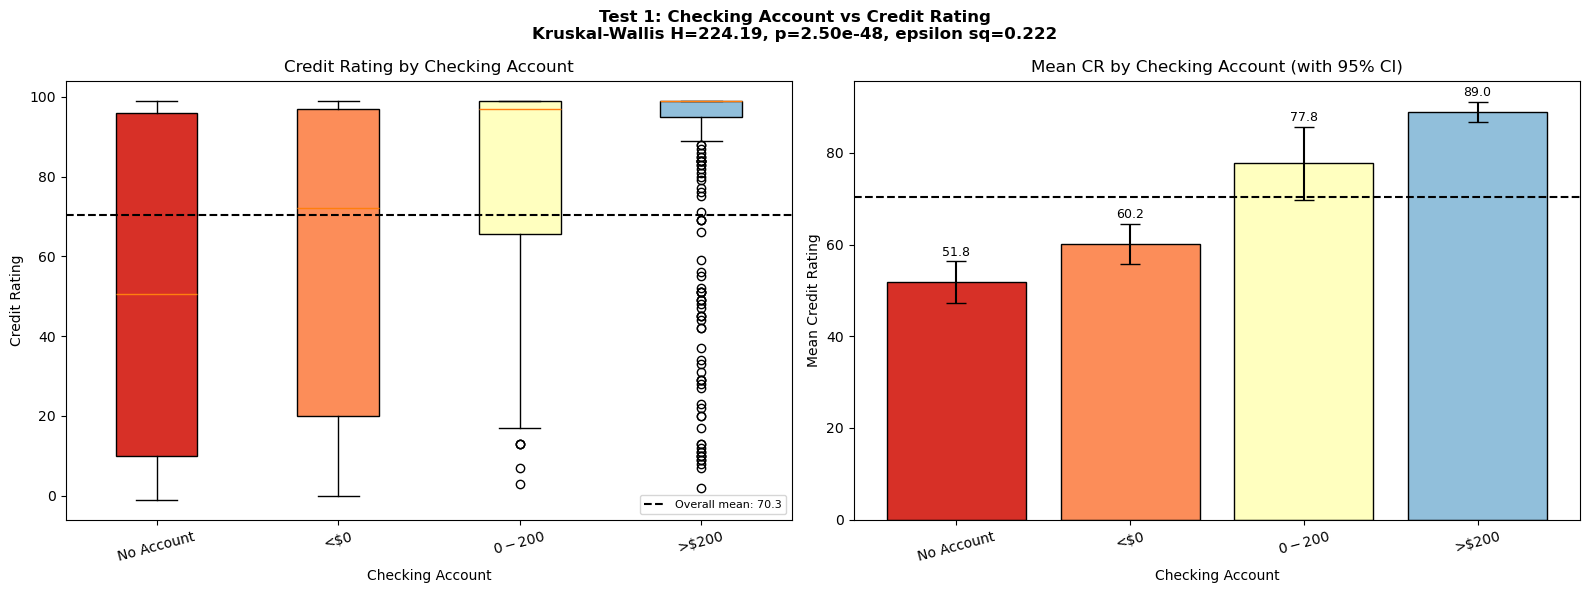

Test 1 - Key Insight

Reject H0 confirmed —
Checking Account is the single strongest categorical predictor of CR. A 37-point gap between
the lowest and highest groups, with 5 of 6 pairwise pairs significant.

Actionable: opening and funding a checking account is the most direct single step
a rejected customer can take to raise their credit rating.


In [19]:
# visualise and print insight
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ch_order  = sorted(df['Checking_Account'].unique())
ch_labels = [labels['Checking_Account'][i] for i in ch_order]
ch_data   = [df[df['Checking_Account'] == i]['Credit_Rating'].values
                 for i in ch_order]

n_groups = len(ch_order)
grp_colors = ['#d73027','#fc8d59','#ffffbf','#91bfdb','#4575b4'][:n_groups]

bp = axes[0].boxplot(ch_data, tick_labels=ch_labels, patch_artist=True)
for patch, color in zip(bp['boxes'], grp_colors):
    patch.set_facecolor(color)
axes[0].axhline(df['Credit_Rating'].mean(), color='black', linestyle='--',
                linewidth=1.5, label=f'Overall mean: {df["Credit_Rating"].mean():.1f}')
axes[0].set_title('Credit Rating by Checking Account')
axes[0].set_xlabel('Checking Account')
axes[0].set_ylabel('Credit Rating')
axes[0].legend(fontsize=8)
axes[0].tick_params(axis='x', rotation=15)

means_v, lo_v, hi_v = [], [], []
for grp in ch_data:
    n, m, se = len(grp), np.mean(grp), stats.sem(grp)
    l, h = stats.t.interval(0.95, df=n-1, loc=m, scale=se)
    means_v.append(m); lo_v.append(m - l); hi_v.append(h - m)

axes[1].bar(ch_labels, means_v, color=grp_colors, edgecolor='black',
            yerr=[lo_v, hi_v], capsize=7)
axes[1].axhline(df['Credit_Rating'].mean(), color='black', linestyle='--', linewidth=1.5)
axes[1].set_title('Mean CR by Checking Account (with 95% CI)')
axes[1].set_xlabel('Checking Account')
axes[1].set_ylabel('Mean Credit Rating')
axes[1].tick_params(axis='x', rotation=15)
for i, (m, h) in enumerate(zip(means_v, hi_v)):
    axes[1].text(i, m + h + 1.2, f'{m:.1f}', ha='center', fontsize=9)

plt.suptitle(
    f'Test 1: Checking Account vs Credit Rating\n'
    f'Kruskal-Wallis H={kw_stat1:.2f}, p={kw_p1:.2e}, '
    f'epsilon sq={eps1:.3f}',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('test1_checking_vs_cr.png', dpi=150, bbox_inches='tight')
plt.show()

print('Test 1 - Key Insight')
print()
print('Reject H0 confirmed —')
print('Checking Account is the single strongest categorical predictor of CR. A 37-point gap between')
print('the lowest and highest groups, with 5 of 6 pairwise pairs significant.')
print()
print('Actionable: opening and funding a checking account is the most direct single step')
print('a rejected customer can take to raise their credit rating.')

### Hypothesis Test 2: Payment Status vs Credit Rating

**EDA finding being tested:** Applicants with better payment records have higher credit ratings. The EDA also flagged the critical account paradox: Critical (CR=84.4) > All Paid (CR=46.5).

Assuming, 

**H0:** The distribution of Credit Rating is the same across all Payment Status groups

**H1:** At least one Payment Status group has a significantly different Credit Rating distribution

**Why Kruskal-Wallis:** Credit Rating failed normality (Shapiro-Wilk p < 0.001) and equal variance (Levene p < 0.05). Kruskal-Wallis is the correct non-parametric replacement for one-way ANOVA — it compares rank distributions rather than means, making no assumption about normality or variance.

**Significance level:** alpha = 0.05

In [22]:
# Kruskal-Wallis test: Payment Status vs Credit Rating
# proving whether the EDA pattern (r=0.32) is statistically real
pa_groups = [
    df[df['Payment_Status'] == i]['Credit_Rating'].values
    for i in sorted(df['Payment_Status'].unique())
]

kw_stat2, kw_p2 = stats.kruskal(*pa_groups)
k2   = df['Payment_Status'].nunique()
eps2 = (kw_stat2 - k2 + 1) / (N - k2)

print('Kruskal-Wallis Test: Payment Status vs Credit Rating')
print(f'H statistic = {kw_stat2:.4f}')
print(f'p-value     = {kw_p2:.8f}')
print(f'epsilon sq  = {eps2:.4f}  (>0.14 = large effect)')
print()
if kw_p2 < 0.05:
    print('Result: p < 0.05 - Reject H0')
    print('Credit Rating distributions differ significantly across Payment Status groups.')
    print('The EDA observation is statistically confirmed.')
print()
print('Group statistics:')
pa_stats = df.groupby('Payment_Status')['Credit_Rating'].agg(['count', 'mean', 'median', 'std'])
pa_stats.index = [labels['Payment_Status'][i] for i in pa_stats.index]
pa_stats.columns = ['N', 'Mean CR', 'Median CR', 'Std Dev']
print(pa_stats.round(2).to_string())

Kruskal-Wallis Test: Payment Status vs Credit Rating
H statistic = 106.4995
p-value     = 0.00000000
epsilon sq  = 0.1030  (>0.14 = large effect)

Result: p < 0.05 - Reject H0
Credit Rating distributions differ significantly across Payment Status groups.
The EDA observation is statistically confirmed.

Group statistics:
                 N  Mean CR  Median CR  Std Dev
No Credits      40    33.67       15.5    35.59
All Paid        49    46.51       23.0    41.56
Existing Paid  530    67.52       89.0    36.34
Delayed         88    70.31       86.5    33.76
Critical       293    84.40       98.0    26.78


In [23]:
# post-hoc pairwise Mann-Whitney U with Bonferroni correction
pa_vals  = sorted(df['Payment_Status'].unique())
pairs2   = list(combinations(pa_vals, 2))
posthoc2 = []

for g1, g2 in pairs2:
    a = df[df['Payment_Status'] == g1]['Credit_Rating']
    b = df[df['Payment_Status'] == g2]['Credit_Rating']
    u, p_raw = stats.mannwhitneyu(a, b, alternative='two-sided')
    p_bonf   = min(p_raw * len(pairs2), 1.0)
    posthoc2.append({
        'Group 1':              labels['Payment_Status'][g1],
        'Group 2':              labels['Payment_Status'][g2],
        'U statistic':          round(u, 1),
        'p (raw)':              round(p_raw, 6),
        'p (Bonferroni)':       round(p_bonf, 6),
        'Significant (a=0.05)': 'Yes' if p_bonf < 0.05 else 'No'
    })

print('Post-hoc Pairwise Tests: Payment Status (Bonferroni corrected)')
print(pd.DataFrame(posthoc2).to_string(index=False))

Post-hoc Pairwise Tests: Payment Status (Bonferroni corrected)
      Group 1       Group 2  U statistic  p (raw)  p (Bonferroni) Significant (a=0.05)
   No Credits      All Paid        781.0 0.100601        1.000000                   No
   No Credits Existing Paid       5407.5 0.000000        0.000002                  Yes
   No Credits       Delayed        784.5 0.000000        0.000004                  Yes
   No Credits      Critical       1643.0 0.000000        0.000000                  Yes
     All Paid Existing Paid       9740.5 0.003451        0.034507                  Yes
     All Paid       Delayed       1465.0 0.001631        0.016313                  Yes
     All Paid      Critical       3662.5 0.000000        0.000000                  Yes
Existing Paid       Delayed      21872.0 0.344968        1.000000                   No
Existing Paid      Critical      53709.5 0.000000        0.000000                  Yes
      Delayed      Critical       9772.0 0.000283        0.002826  

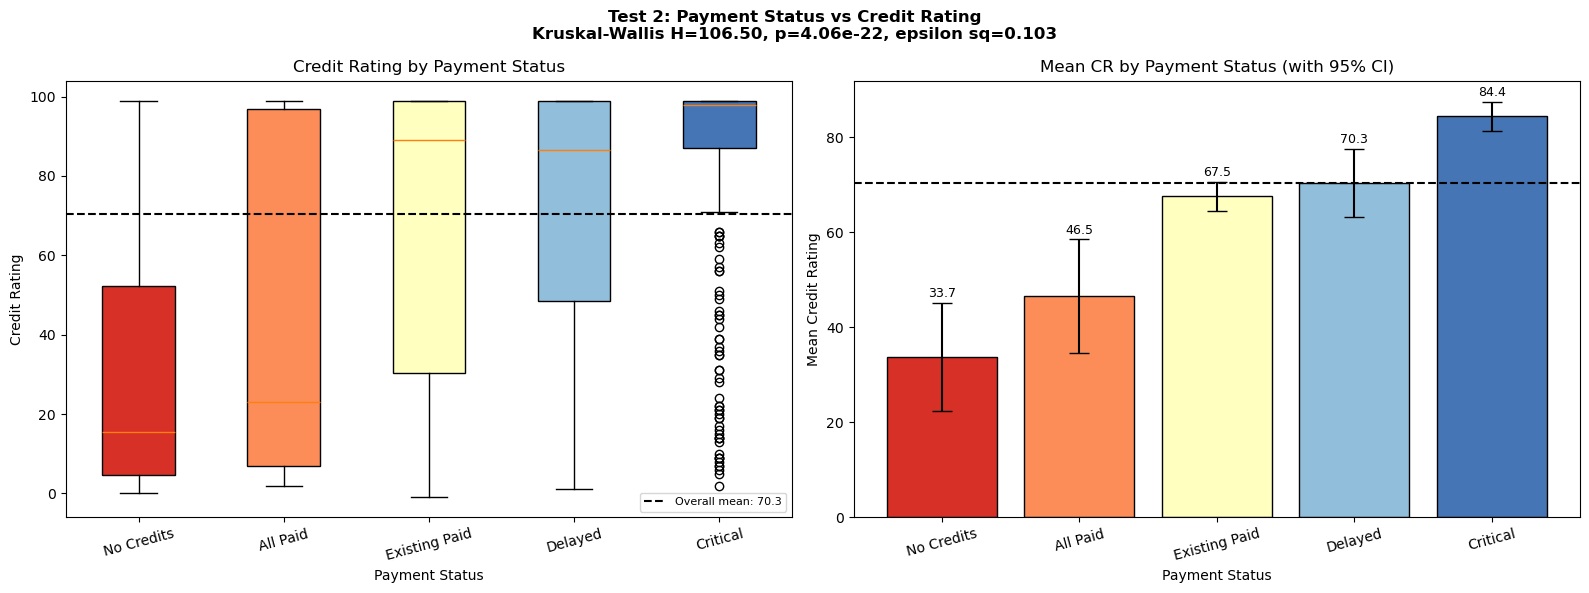

Test 2 - Key Insight

Reject H0 confirmed —
Payment Status significantly predicts CR.
Critical account paradox holds: No Credits (CR=33.7) is the lowest group, not Critical.
No borrowing history is penalised more than a critical account because the bank has zero evidence of repayment behaviour.

Actionable: customers with no credit history should open a small credit line
and repay it consistently before applying for a larger loan.


In [26]:
# visualise and print insight
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

pa_order  = sorted(df['Payment_Status'].unique())
pa_labels = [labels['Payment_Status'][i] for i in pa_order]
pa_data   = [df[df['Payment_Status'] == i]['Credit_Rating'].values
                 for i in pa_order]

n_groups = len(pa_order)
grp_colors = ['#d73027','#fc8d59','#ffffbf','#91bfdb','#4575b4'][:n_groups]

bp = axes[0].boxplot(pa_data, tick_labels=pa_labels, patch_artist=True)
for patch, color in zip(bp['boxes'], grp_colors):
    patch.set_facecolor(color)
axes[0].axhline(df['Credit_Rating'].mean(), color='black', linestyle='--',
                linewidth=1.5, label=f'Overall mean: {df["Credit_Rating"].mean():.1f}')
axes[0].set_title('Credit Rating by Payment Status')
axes[0].set_xlabel('Payment Status')
axes[0].set_ylabel('Credit Rating')
axes[0].legend(fontsize=8)
axes[0].tick_params(axis='x', rotation=15)

means_v, lo_v, hi_v = [], [], []
for grp in pa_data:
    n, m, se = len(grp), np.mean(grp), stats.sem(grp)
    l, h = stats.t.interval(0.95, df=n-1, loc=m, scale=se)
    means_v.append(m); lo_v.append(m - l); hi_v.append(h - m)

axes[1].bar(pa_labels, means_v, color=grp_colors, edgecolor='black',
            yerr=[lo_v, hi_v], capsize=7)
axes[1].axhline(df['Credit_Rating'].mean(), color='black', linestyle='--', linewidth=1.5)
axes[1].set_title('Mean CR by Payment Status (with 95% CI)')
axes[1].set_xlabel('Payment Status')
axes[1].set_ylabel('Mean Credit Rating')
axes[1].tick_params(axis='x', rotation=15)
for i, (m, h) in enumerate(zip(means_v, hi_v)):
    axes[1].text(i, m + h + 1.2, f'{m:.1f}', ha='center', fontsize=9)

plt.suptitle(
    f'Test 2: Payment Status vs Credit Rating\n'
    f'Kruskal-Wallis H={kw_stat2:.2f}, p={kw_p2:.2e}, '
    f'epsilon sq={eps2:.3f}',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('test2_payment_vs_cr.png', dpi=150, bbox_inches='tight')
plt.show()

print('Test 2 - Key Insight')
print()
print('Reject H0 confirmed —')
print('Payment Status significantly predicts CR.')
print('Critical account paradox holds: No Credits (CR=33.7) is the lowest group, not Critical.') 
print('No borrowing history is penalised more than a critical account because the bank has zero evidence of repayment behaviour.')
print()
print('Actionable: customers with no credit history should open a small credit line')
print('and repay it consistently before applying for a larger loan.')

### Hypothesis Test 3: Savings Account vs Credit Rating

**EDA finding being tested:** Applicants with higher savings balances have higher credit ratings. EDA anomaly: savings can compensate for no checking account (no checking + high savings CR=70.8).

Assuming, 

**H0:** The distribution of Credit Rating is the same across all Savings Account groups

**H1:** At least one Savings Account group has a significantly different Credit Rating distribution

**Why Kruskal-Wallis:** Credit Rating failed normality (Shapiro-Wilk p < 0.001) and equal variance (Levene p < 0.05). Kruskal-Wallis is the correct non-parametric replacement for one-way ANOVA — it compares rank distributions rather than means, making no assumption about normality or variance.

**Significance level:** alpha = 0.05

In [27]:
# Kruskal-Wallis test: Savings Account vs Credit Rating
# proving whether the EDA pattern (r=0.26) is statistically real
sa_groups = [
    df[df['Savings_Account'] == i]['Credit_Rating'].values
    for i in sorted(df['Savings_Account'].unique())
]

kw_stat3, kw_p3 = stats.kruskal(*sa_groups)
k3   = df['Savings_Account'].nunique()
eps3 = (kw_stat3 - k3 + 1) / (N - k3)

print('Kruskal-Wallis Test: Savings Account vs Credit Rating')
print(f'H statistic = {kw_stat3:.4f}')
print(f'p-value     = {kw_p3:.8f}')
print(f'epsilon sq  = {eps3:.4f}  (>0.14 = large effect)')
print()
if kw_p3 < 0.05:
    print('Result: p < 0.05 - Reject H0')
    print('Credit Rating distributions differ significantly across Savings Account groups.')
    print('The EDA observation is statistically confirmed.')
print()
print('Group statistics:')
sa_stats = df.groupby('Savings_Account')['Credit_Rating'].agg(['count', 'mean', 'median', 'std'])
sa_stats.index = [labels['Savings_Account'][i] for i in sa_stats.index]
sa_stats.columns = ['N', 'Mean CR', 'Median CR', 'Std Dev']
print(sa_stats.round(2).to_string())

Kruskal-Wallis Test: Savings Account vs Credit Rating
H statistic = 74.2054
p-value     = 0.00000000
epsilon sq  = 0.0706  (>0.14 = large effect)

Result: p < 0.05 - Reject H0
Credit Rating distributions differ significantly across Savings Account groups.
The EDA observation is statistically confirmed.

Group statistics:
              N  Mean CR  Median CR  Std Dev
<$100       603    63.18       82.0    37.95
$100-$500   103    69.50       93.0    36.39
$500-$1000   63    84.71       98.0    26.30
>$1000       48    90.31       98.5    18.33
Unknown     183    84.17       98.0    26.14


In [28]:
# post-hoc pairwise Mann-Whitney U with Bonferroni correction
sa_vals  = sorted(df['Savings_Account'].unique())
pairs3   = list(combinations(sa_vals, 2))
posthoc3 = []

for g1, g2 in pairs3:
    a = df[df['Savings_Account'] == g1]['Credit_Rating']
    b = df[df['Savings_Account'] == g2]['Credit_Rating']
    u, p_raw = stats.mannwhitneyu(a, b, alternative='two-sided')
    p_bonf   = min(p_raw * len(pairs3), 1.0)
    posthoc3.append({
        'Group 1':              labels['Savings_Account'][g1],
        'Group 2':              labels['Savings_Account'][g2],
        'U statistic':          round(u, 1),
        'p (raw)':              round(p_raw, 6),
        'p (Bonferroni)':       round(p_bonf, 6),
        'Significant (a=0.05)': 'Yes' if p_bonf < 0.05 else 'No'
    })

print('Post-hoc Pairwise Tests: Savings Account (Bonferroni corrected)')
print(pd.DataFrame(posthoc3).to_string(index=False))

Post-hoc Pairwise Tests: Savings Account (Bonferroni corrected)
   Group 1    Group 2  U statistic  p (raw)  p (Bonferroni) Significant (a=0.05)
     <$100  $100-$500      27905.0 0.095934        0.959344                   No
     <$100 $500-$1000      12233.0 0.000002        0.000024                  Yes
     <$100     >$1000       8571.0 0.000002        0.000019                  Yes
     <$100    Unknown      37351.0 0.000000        0.000000                  Yes
 $100-$500 $500-$1000       2373.0 0.002825        0.028246                  Yes
 $100-$500     >$1000       1694.0 0.001398        0.013980                  Yes
 $100-$500    Unknown       7271.0 0.000909        0.009087                  Yes
$500-$1000     >$1000       1453.0 0.710066        1.000000                   No
$500-$1000    Unknown       6045.0 0.545094        1.000000                   No
    >$1000    Unknown       4780.5 0.321651        1.000000                   No


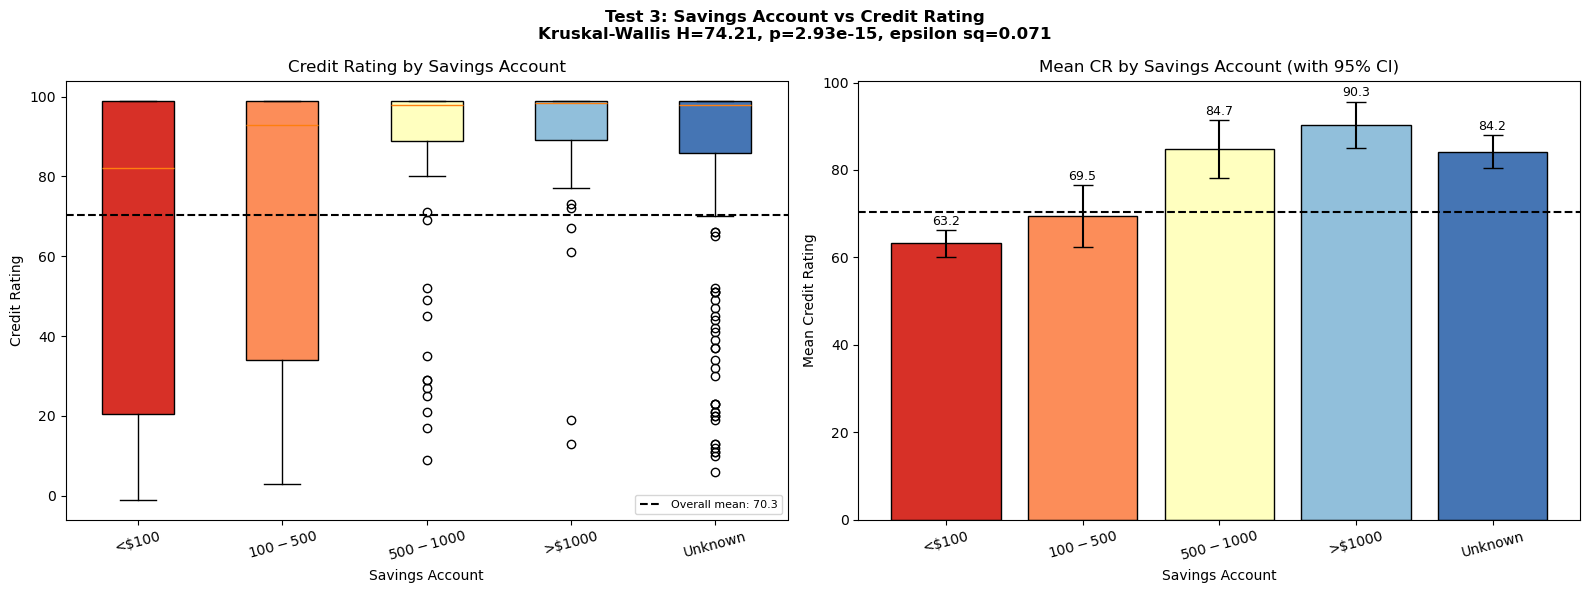

Test 3 - Key Insight

Reject H0 confirmed —
Savings Account significantly predicts CR.
>$1000 savings group achieves mean CR=90.3 vs 63.2 for <$100.
The EDA compensation anomaly is statistically backed.

Actionable: savings is a viable alternative pathway for customers who cannot immediately open a checking account.


In [29]:
# visualise and print insight
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sa_order  = sorted(df['Savings_Account'].unique())
sa_labels = [labels['Savings_Account'][i] for i in sa_order]
sa_data   = [df[df['Savings_Account'] == i]['Credit_Rating'].values
                 for i in sa_order]

n_groups = len(sa_order)
grp_colors = ['#d73027','#fc8d59','#ffffbf','#91bfdb','#4575b4'][:n_groups]

bp = axes[0].boxplot(sa_data, tick_labels=sa_labels, patch_artist=True)
for patch, color in zip(bp['boxes'], grp_colors):
    patch.set_facecolor(color)
axes[0].axhline(df['Credit_Rating'].mean(), color='black', linestyle='--',
                linewidth=1.5, label=f'Overall mean: {df["Credit_Rating"].mean():.1f}')
axes[0].set_title('Credit Rating by Savings Account')
axes[0].set_xlabel('Savings Account')
axes[0].set_ylabel('Credit Rating')
axes[0].legend(fontsize=8)
axes[0].tick_params(axis='x', rotation=15)

means_v, lo_v, hi_v = [], [], []
for grp in sa_data:
    n, m, se = len(grp), np.mean(grp), stats.sem(grp)
    l, h = stats.t.interval(0.95, df=n-1, loc=m, scale=se)
    means_v.append(m); lo_v.append(m - l); hi_v.append(h - m)

axes[1].bar(sa_labels, means_v, color=grp_colors, edgecolor='black',
            yerr=[lo_v, hi_v], capsize=7)
axes[1].axhline(df['Credit_Rating'].mean(), color='black', linestyle='--', linewidth=1.5)
axes[1].set_title('Mean CR by Savings Account (with 95% CI)')
axes[1].set_xlabel('Savings Account')
axes[1].set_ylabel('Mean Credit Rating')
axes[1].tick_params(axis='x', rotation=15)
for i, (m, h) in enumerate(zip(means_v, hi_v)):
    axes[1].text(i, m + h + 1.2, f'{m:.1f}', ha='center', fontsize=9)

plt.suptitle(
    f'Test 3: Savings Account vs Credit Rating\n'
    f'Kruskal-Wallis H={kw_stat3:.2f}, p={kw_p3:.2e}, '
    f'epsilon sq={eps3:.3f}',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('test3_savings_vs_cr.png', dpi=150, bbox_inches='tight')
plt.show()

print('Test 3 - Key Insight')
print()
print('Reject H0 confirmed —') 
print('Savings Account significantly predicts CR.') 
print('>$1000 savings group achieves mean CR=90.3 vs 63.2 for <$100.')
print('The EDA compensation anomaly is statistically backed.')
print()
print('Actionable: savings is a viable alternative pathway for customers who cannot immediately open a checking account.')

### Hypothesis Test 4 : Employment vs Credit Rating

**EDA finding being tested:** Longer employment tenure predicts higher credit ratings. EDA cross-factor finding: older unemployed applicants (likely retired) score higher than expected due to savings, not employment.

Assuming, 

**H0:** The distribution of Credit Rating is the same across all Employment groups

**H1:** At least one Employment group has a significantly different Credit Rating distribution

**Why Kruskal-Wallis:** Credit Rating failed normality (Shapiro-Wilk p < 0.001) and equal variance (Levene p < 0.05). Kruskal-Wallis is the correct non-parametric replacement for one-way ANOVA — it compares rank distributions rather than means, making no assumption about normality or variance.

**Significance level:** alpha = 0.05

In [31]:
# Kruskal-Wallis test: Employment vs Credit Rating
# proving whether the EDA pattern (r=0.21) is statistically real
em_groups = [
    df[df['Employment'] == i]['Credit_Rating'].values
    for i in sorted(df['Employment'].unique())
]

kw_stat4, kw_p4 = stats.kruskal(*em_groups)
k4   = df['Employment'].nunique()
eps4 = (kw_stat4 - k4 + 1) / (N - k4)

print('Kruskal-Wallis Test: Employment vs Credit Rating')
print(f'H statistic = {kw_stat4:.4f}')
print(f'p-value     = {kw_p4:.8f}')
print(f'epsilon sq  = {eps4:.4f}  (>0.14 = large effect)')
print()
if kw_p4 < 0.05:
    print('Result: p < 0.05 - Reject H0')
    print('Credit Rating distributions differ significantly across Employment groups.')
    print('The EDA observation is statistically confirmed.')
print()
print('Group statistics:')
em_stats = df.groupby('Employment')['Credit_Rating'].agg(['count', 'mean', 'median', 'std'])
em_stats.index = [labels['Employment'][i] for i in em_stats.index]
em_stats.columns = ['N', 'Mean CR', 'Median CR', 'Std Dev']
print(em_stats.round(2).to_string())

Kruskal-Wallis Test: Employment vs Credit Rating
H statistic = 50.3513
p-value     = 0.00000000
epsilon sq  = 0.0466  (>0.14 = large effect)

Result: p < 0.05 - Reject H0
Credit Rating distributions differ significantly across Employment groups.
The EDA observation is statistically confirmed.

Group statistics:
              N  Mean CR  Median CR  Std Dev
Unemployed   62    56.60       73.5    38.67
<1yr        172    58.55       73.5    40.11
1-4yr       339    69.40       93.0    35.73
4-7yr       174    76.56       97.0    32.30
>7yr        253    78.67       97.0    31.16


In [32]:
# post-hoc pairwise Mann-Whitney U with Bonferroni correction
em_vals  = sorted(df['Employment'].unique())
pairs4   = list(combinations(em_vals, 2))
posthoc4 = []

for g1, g2 in pairs4:
    a = df[df['Employment'] == g1]['Credit_Rating']
    b = df[df['Employment'] == g2]['Credit_Rating']
    u, p_raw = stats.mannwhitneyu(a, b, alternative='two-sided')
    p_bonf   = min(p_raw * len(pairs4), 1.0)
    posthoc4.append({
        'Group 1':              labels['Employment'][g1],
        'Group 2':              labels['Employment'][g2],
        'U statistic':          round(u, 1),
        'p (raw)':              round(p_raw, 6),
        'p (Bonferroni)':       round(p_bonf, 6),
        'Significant (a=0.05)': 'Yes' if p_bonf < 0.05 else 'No'
    })

print('Post-hoc Pairwise Tests: Employment (Bonferroni corrected)')
print(pd.DataFrame(posthoc4).to_string(index=False))

Post-hoc Pairwise Tests: Employment (Bonferroni corrected)
   Group 1 Group 2  U statistic  p (raw)  p (Bonferroni) Significant (a=0.05)
Unemployed    <1yr       5017.5 0.489907        1.000000                   No
Unemployed   1-4yr       8004.5 0.002490        0.024905                  Yes
Unemployed   4-7yr       3467.5 0.000022        0.000215                  Yes
Unemployed    >7yr       4704.0 0.000001        0.000005                  Yes
      <1yr   1-4yr      24304.0 0.001841        0.018407                  Yes
      <1yr   4-7yr      10853.5 0.000007        0.000072                  Yes
      <1yr    >7yr      14957.5 0.000000        0.000000                  Yes
     1-4yr   4-7yr      26093.5 0.028888        0.288875                   No
     1-4yr    >7yr      36226.5 0.000907        0.009070                  Yes
     4-7yr    >7yr      21101.0 0.451522        1.000000                   No


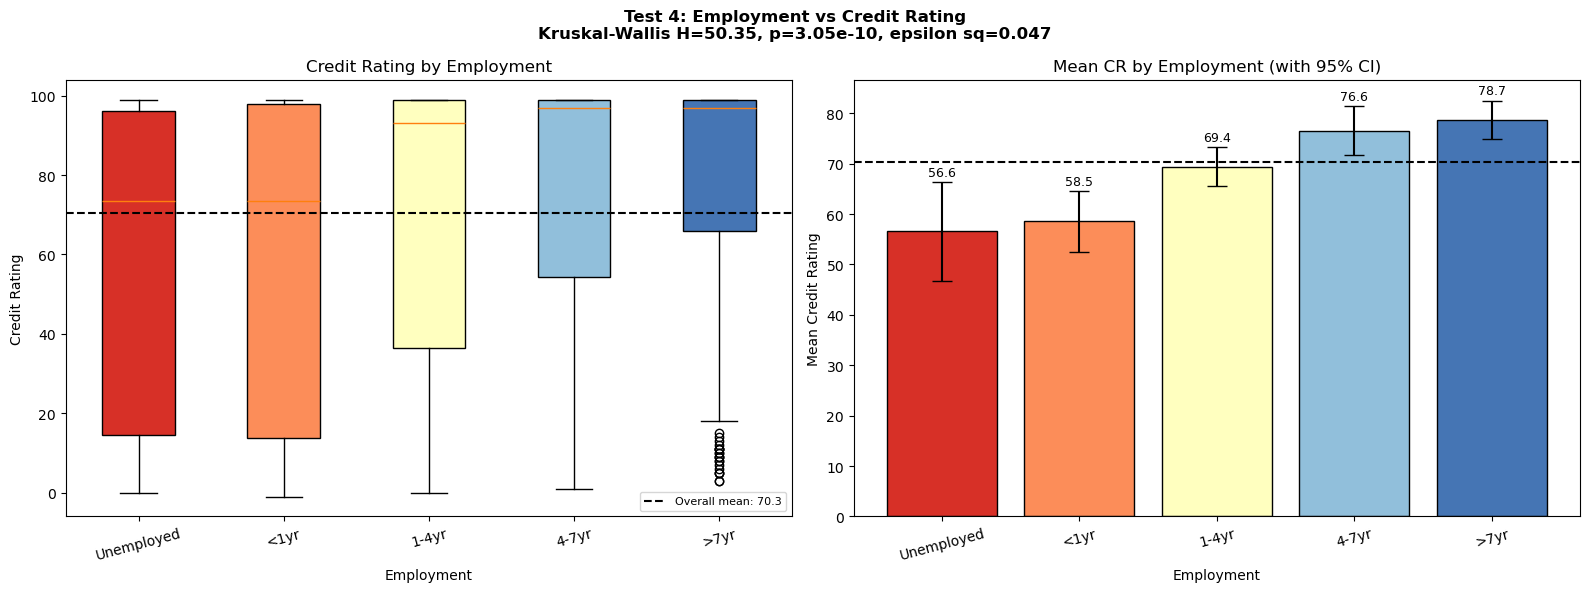

Test 4 - Key Insight

Reject H0 confirmed —
Employment significantly predicts CR. >7yr employment mean CR=78.7 vs
Unemployed CR=56.6. EDA retired paradox holds: the effect is moderated by age and savings.

Actionable: employment stability is a meaningful signal but should be assessed alongside age and savings,
not in isolation.


In [34]:
# visualise and print insight
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

em_order  = sorted(df['Employment'].unique())
em_labels = [labels['Employment'][i] for i in em_order]
em_data   = [df[df['Employment'] == i]['Credit_Rating'].values
                 for i in em_order]

n_groups = len(em_order)
grp_colors = ['#d73027','#fc8d59','#ffffbf','#91bfdb','#4575b4'][:n_groups]

bp = axes[0].boxplot(em_data, tick_labels=em_labels, patch_artist=True)
for patch, color in zip(bp['boxes'], grp_colors):
    patch.set_facecolor(color)
axes[0].axhline(df['Credit_Rating'].mean(), color='black', linestyle='--',
                linewidth=1.5, label=f'Overall mean: {df["Credit_Rating"].mean():.1f}')
axes[0].set_title('Credit Rating by Employment')
axes[0].set_xlabel('Employment')
axes[0].set_ylabel('Credit Rating')
axes[0].legend(fontsize=8)
axes[0].tick_params(axis='x', rotation=15)

means_v, lo_v, hi_v = [], [], []
for grp in em_data:
    n, m, se = len(grp), np.mean(grp), stats.sem(grp)
    l, h = stats.t.interval(0.95, df=n-1, loc=m, scale=se)
    means_v.append(m); lo_v.append(m - l); hi_v.append(h - m)

axes[1].bar(em_labels, means_v, color=grp_colors, edgecolor='black',
            yerr=[lo_v, hi_v], capsize=7)
axes[1].axhline(df['Credit_Rating'].mean(), color='black', linestyle='--', linewidth=1.5)
axes[1].set_title('Mean CR by Employment (with 95% CI)')
axes[1].set_xlabel('Employment')
axes[1].set_ylabel('Mean Credit Rating')
axes[1].tick_params(axis='x', rotation=15)
for i, (m, h) in enumerate(zip(means_v, hi_v)):
    axes[1].text(i, m + h + 1.2, f'{m:.1f}', ha='center', fontsize=9)

plt.suptitle(
    f'Test 4: Employment vs Credit Rating\n'
    f'Kruskal-Wallis H={kw_stat4:.2f}, p={kw_p4:.2e}, '
    f'epsilon sq={eps4:.3f}',
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.savefig('test4_employment_vs_cr.png', dpi=150, bbox_inches='tight')
plt.show()

print('Test 4 - Key Insight')
print()
print('Reject H0 confirmed —')
print('Employment significantly predicts CR. >7yr employment mean CR=78.7 vs')
print('Unemployed CR=56.6. EDA retired paradox holds: the effect is moderated by age and savings.')
print()
print('Actionable: employment stability is a meaningful signal but should be assessed alongside age and savings,') 
print('not in isolation.')

### Hypothesis Test 5 : Loan Duration and Amount vs Approval

**EDA finding being tested:** Approved applicants take smaller, shorter loans. Duration (r=-0.24 with CR) and Amount (r=-0.15 with CR) are the two strongest negative correlates in the dataset. The EDA heatmap showed these penalties compound — a bigger AND longer loan pushes CR significantly lower than either alone.

**Why this test uses Approval as the grouping variable (not CR):**
Tests 1-4 proved financial behaviour predicts CR. This test asks the next question: do the loan characteristics themselves differ significantly between those the bank approved and those it rejected? Here Approval is used as a binary grouping variable to split the sample, and Duration/Amount are the continuous outcomes being compared. This is the right arrow in our causal chain: CR -> Approval.

**Test A — Loan Duration:**
H0: Loan duration is the same for approved and rejected applicants
H1: Loan duration differs between approved and rejected applicants

**Test B — Loan Amount:**
H0: Loan amount is the same for approved and rejected applicants
H1: Loan amount differs between approved and rejected applicants

**Why Mann-Whitney U:** two-group comparison on a continuous variable where normality cannot be assumed. Mann-Whitney U is the non-parametric replacement for an independent t-test — it compares rank distributions rather than means.

**Spearman correlations** are also reported to show the continuous relationship between Duration/Amount and Credit Rating directly (not just via the approval split).

**Significance level:** alpha = 0.05

In [36]:
# Spearman correlations: Duration and Amount vs Credit Rating
# Spearman is used because CR failed normality and Pearson requires bivariate normality
r_dur, p_dur = stats.spearmanr(df['Duration'], df['Credit_Rating'])
r_amt, p_amt = stats.spearmanr(df['Amount'],   df['Credit_Rating'])

print('Spearman Correlations with Credit Rating')
print(f'Duration: r={r_dur:.3f}, p={p_dur:.4e}')
print(f'Amount:   r={r_amt:.3f}, p={p_amt:.4e}')
print()
print('Both are statistically significant negative correlations.')
print('Longer loans and larger loans are independently associated with lower CR.')
print('This confirms the EDA observations before we even split by approval.')
print()

# Mann-Whitney U: approved vs rejected on Duration and Amount
approved_df = df[df['Approval'] == 1]
rejected_df = df[df['Approval'] == 0]

mw_results = []
for col, label in [('Duration', 'Loan Duration (months)'), ('Amount', 'Loan Amount')]:
    u, p = stats.mannwhitneyu(approved_df[col], rejected_df[col], alternative='two-sided')
    n1, n2 = len(approved_df[col]), len(rejected_df[col])
    r_rb   = 1 - (2 * u) / (n1 * n2)
    mw_results.append({
        'Variable':          label,
        'Mean (Approved)':   round(approved_df[col].mean(), 2),
        'Mean (Rejected)':   round(rejected_df[col].mean(), 2),
        'U statistic':       round(u, 1),
        'p-value':           round(p, 6),
        'Rank-biserial r':   round(r_rb, 4),
        'Significant':       'Yes' if p < 0.05 else 'No'
    })
    print(f'Mann-Whitney U: {label}')
    print(f'  Approved: mean={approved_df[col].mean():.2f}, median={approved_df[col].median():.2f}')
    print(f'  Rejected: mean={rejected_df[col].mean():.2f}, median={rejected_df[col].median():.2f}')
    print(f'  U={u:.1f}, p={p:.6f}, rank-biserial r={r_rb:.4f}')
    print(f'  Decision: {"Reject H0" if p < 0.05 else "Fail to reject H0"}')
    print()

Spearman Correlations with Credit Rating
Duration: r=-0.207, p=3.7282e-11
Amount:   r=-0.095, p=2.7038e-03

Both are statistically significant negative correlations.
Longer loans and larger loans are independently associated with lower CR.
This confirms the EDA observations before we even split by approval.

Mann-Whitney U: Loan Duration (months)
  Approved: mean=19.28, median=18.00
  Rejected: mean=24.12, median=24.00
  U=84100.5, p=0.000000, rank-biserial r=0.2257
  Decision: Reject H0

Mann-Whitney U: Loan Amount
  Approved: mean=3006.69, median=2241.00
  Rejected: mean=3847.96, median=2580.00
  U=97023.5, p=0.006451, rank-biserial r=0.1068
  Decision: Reject H0



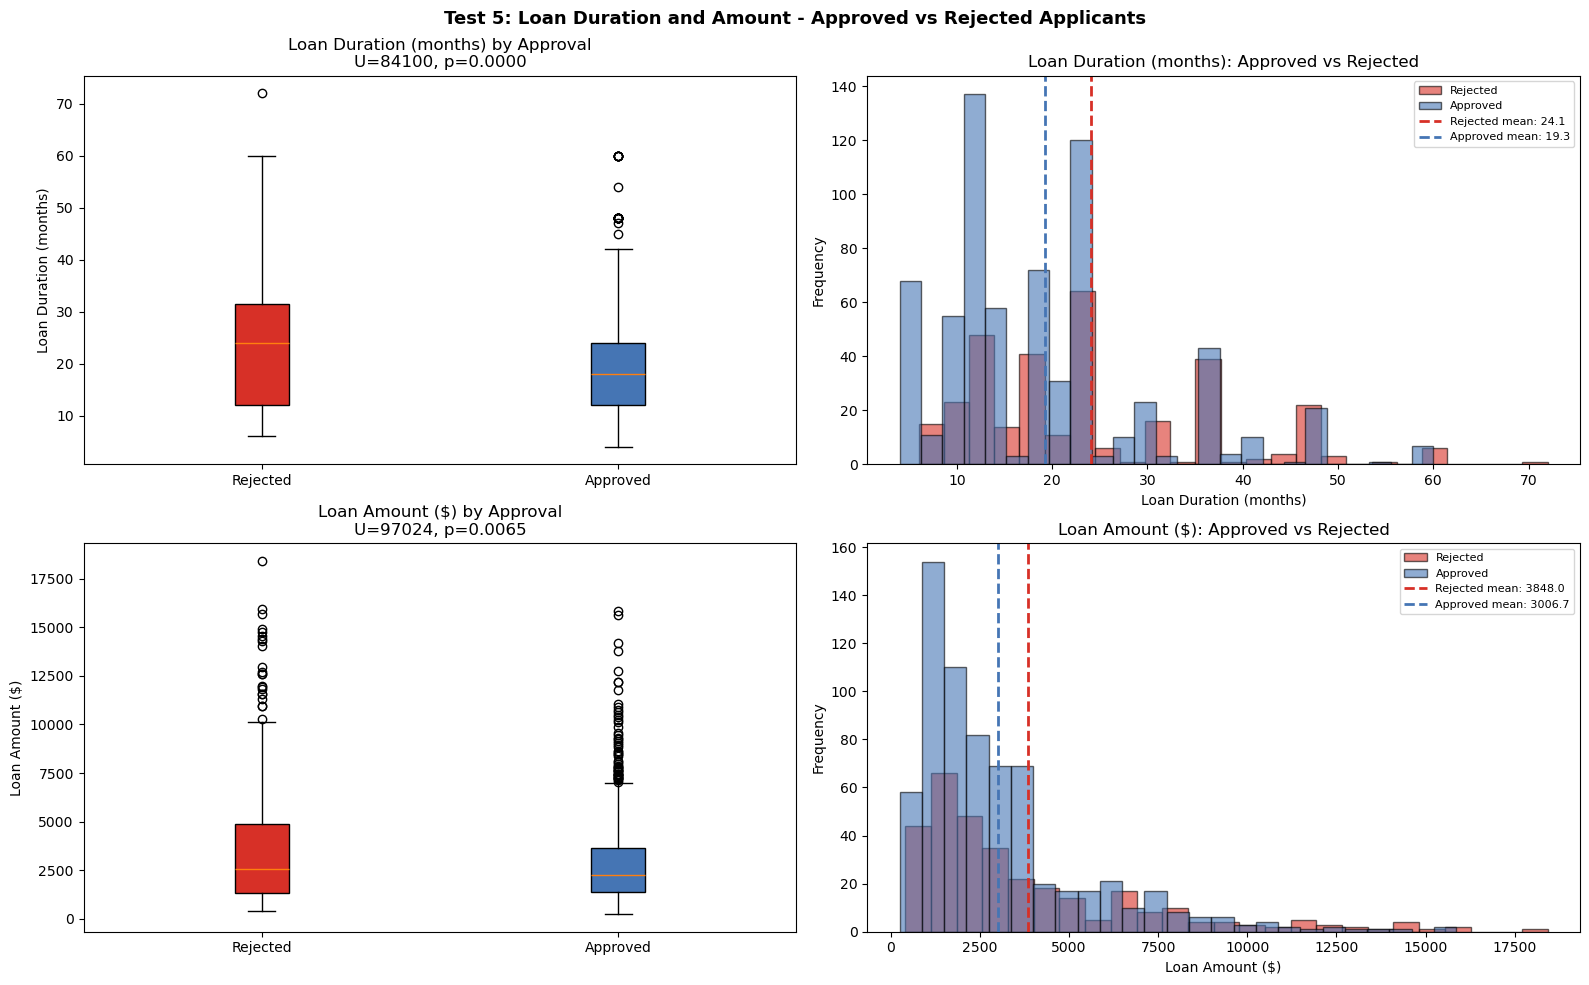

Test 5 - Key Insight

Duration: approved=19.3m vs rejected=24.1m
Amount:   approved=$3007 vs rejected=$3848

Rejected applicants ask for more money over a longer period.
Reducing loan amount or term can shift a borderline case into approval.


In [50]:
# visualise insights
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for row_i, (col, label, key) in enumerate([
    ('Duration', 'Loan Duration (months)', 'Loan Duration'),
    ('Amount',   'Loan Amount ($)',        'Loan Amount')
]):
    app_data = approved_df[col].values
    rej_data = rejected_df[col].values
    bp = axes[row_i, 0].boxplot([rej_data, app_data],
                                 tick_labels=['Rejected', 'Approved'], patch_artist=True)
    bp['boxes'][0].set_facecolor('#d73027')
    bp['boxes'][1].set_facecolor('#4575b4')
    mw_row = mw_results[key]
    axes[row_i, 0].set_title(
        f'{label} by Approval\nU={mw_row["U statistic"]:.0f}, p={mw_row["p-value"]:.4f}')
    axes[row_i, 0].set_ylabel(label)

    axes[row_i, 1].hist(rej_data, bins=25, alpha=0.6, color='#d73027',
                         label='Rejected', edgecolor='black')
    axes[row_i, 1].hist(app_data, bins=25, alpha=0.6, color='#4575b4',
                         label='Approved', edgecolor='black')
    axes[row_i, 1].axvline(np.mean(rej_data), color='#d73027', linestyle='--',
                            linewidth=2, label=f'Rejected mean: {np.mean(rej_data):.1f}')
    axes[row_i, 1].axvline(np.mean(app_data), color='#4575b4', linestyle='--',
                            linewidth=2, label=f'Approved mean: {np.mean(app_data):.1f}')
    axes[row_i, 1].set_title(f'{label}: Approved vs Rejected')
    axes[row_i, 1].set_xlabel(label)
    axes[row_i, 1].set_ylabel('Frequency')
    axes[row_i, 1].legend(fontsize=8)

plt.suptitle('Test 5: Loan Duration and Amount - Approved vs Rejected Applicants',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('test5_loan_vs_approval.png', dpi=150, bbox_inches='tight')
plt.show()

print('Test 5 - Key Insight')
print()
print(f'Duration: approved={approved_df["Duration"].mean():.1f}m vs rejected={rejected_df["Duration"].mean():.1f}m')
print(f'Amount:   approved=${approved_df["Amount"].mean():.0f} vs rejected=${rejected_df["Amount"].mean():.0f}')
print()
print('Rejected applicants ask for more money over a longer period.')
print('Reducing loan amount or term can shift a borderline case into approval.')

## Final Summary - Answering the Analytical Question

In [56]:
mw_row_d = mw_results['Loan Duration']
mw_row_a = mw_results['Loan Amount']

print('Inferential Statistics - Full Results Summary')
print('All five tests rejected H0 at alpha = 0.05')
print(f"""
Test selection process:
  Shapiro-Wilk: p < 0.001 — normality Failed
  Levene:       p < 0.05  — equal variance Failed
  ANOVA:        ran but results unreliable — switched to Kruskal-Wallis
  t-test:       not used — switched to Mann-Whitney U

Test 1 — Checking Account vs Credit Rating (r=0.45)
  Kruskal-Wallis H={kw_stat1:.2f}, p={kw_p1:.2e}, eps2={eps1:.3f} (large)
  Reject H0 — 37-point CR gap across groups, 5/6 pairs significant

Test 2 — Payment Status vs Credit Rating (r=0.32)
  Kruskal-Wallis H={kw_stat2:.2f}, p={kw_p2:.2e}, eps2={eps2:.3f}
  Reject H0 — No Credits lowest (CR=33.7), critical account paradox confirmed

Test 3 — Savings Account vs Credit Rating (r=0.26)
  Kruskal-Wallis H={kw_stat3:.2f}, p={kw_p3:.2e}, eps2={eps3:.3f}
  Reject H0 — 27-point gap, savings compensation anomaly confirmed

Test 4 — Employment vs Credit Rating (r=0.21)
  Kruskal-Wallis H={kw_stat4:.2f}, p={kw_p4:.2e}, eps2={eps4:.3f}
  Reject H0 — 22-point gap, retired unemployed paradox confirmed

Test 5 — Loan Duration and Amount vs Approval
  Spearman: Duration r=-0.207 (p<0.001), Amount r=-0.095 (p=0.003)
  Mann-Whitney Duration: U={mw_row_d['U statistic']:.0f}, p={mw_row_d['p-value']:.4f} — Reject H0
  Mann-Whitney Amount:   U={mw_row_a['U statistic']:.0f}, p={mw_row_a['p-value']:.4f} — Reject H0
""")

Inferential Statistics - Full Results Summary
All five tests rejected H0 at alpha = 0.05

Test selection process:
  Shapiro-Wilk: p < 0.001 — normality Failed
  Levene:       p < 0.05  — equal variance Failed
  ANOVA:        ran but results unreliable — switched to Kruskal-Wallis
  t-test:       not used — switched to Mann-Whitney U

Test 1 — Checking Account vs Credit Rating (r=0.45)
  Kruskal-Wallis H=224.19, p=2.50e-48, eps2=0.222 (large)
  Reject H0 — 37-point CR gap across groups, 5/6 pairs significant

Test 2 — Payment Status vs Credit Rating (r=0.32)
  Kruskal-Wallis H=106.50, p=4.06e-22, eps2=0.103
  Reject H0 — No Credits lowest (CR=33.7), critical account paradox confirmed

Test 3 — Savings Account vs Credit Rating (r=0.26)
  Kruskal-Wallis H=74.21, p=2.93e-15, eps2=0.071
  Reject H0 — 27-point gap, savings compensation anomaly confirmed

Test 4 — Employment vs Credit Rating (r=0.21)
  Kruskal-Wallis H=50.35, p=3.05e-10, eps2=0.047
  Reject H0 — 22-point gap, retired unemploy

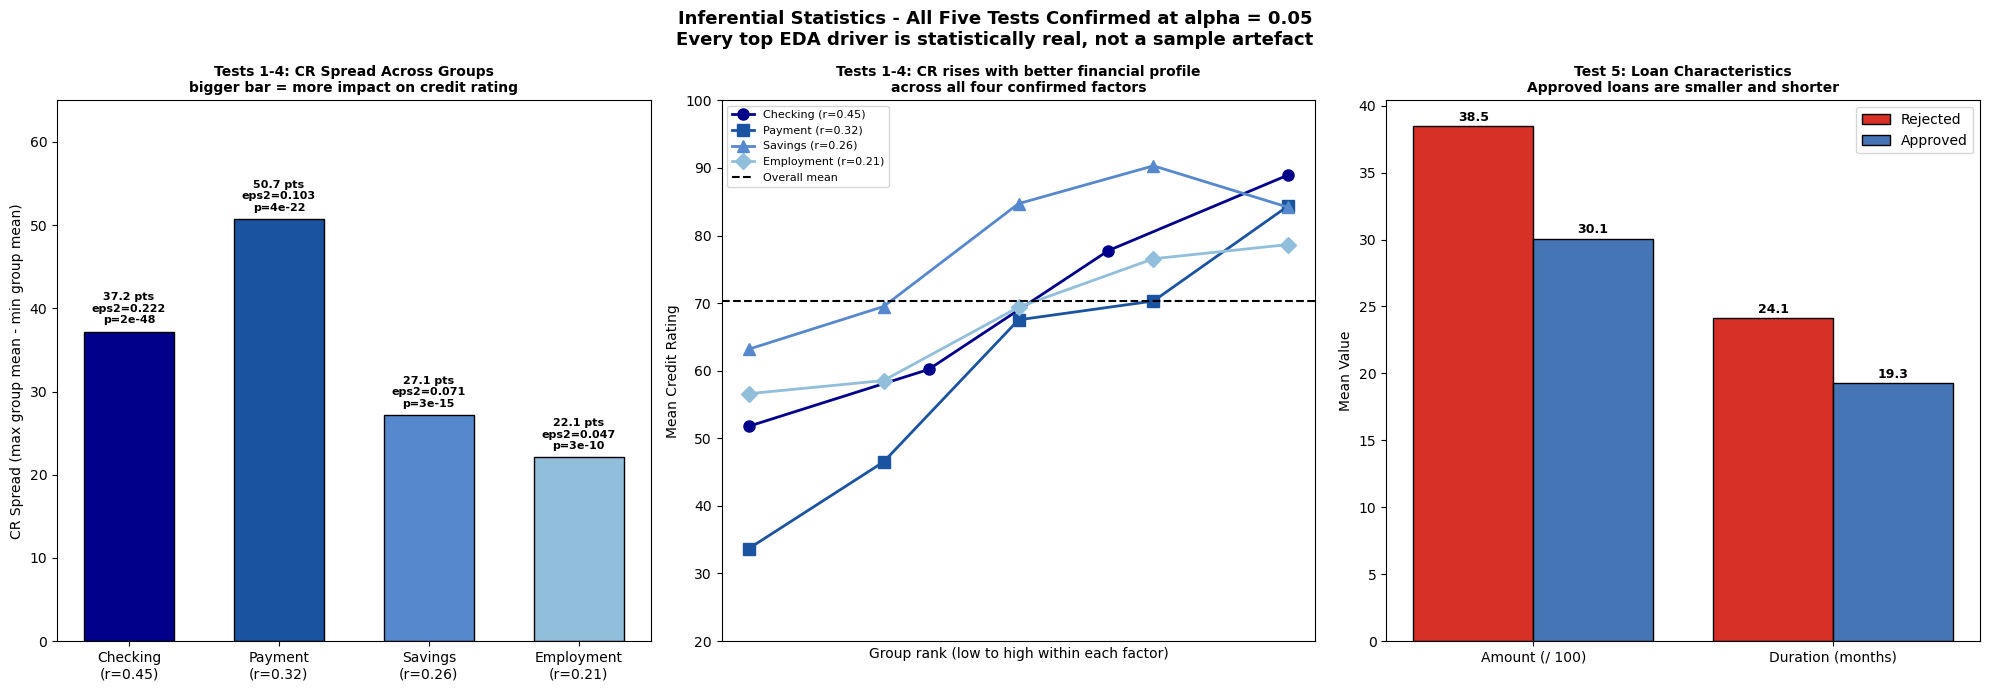

In [57]:
# Final Summary Chart 
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# panel 1: CR spread for Tests 1-4 — bigger bar = bigger impact
test_labels_s = ['Checking\n(r=0.45)', 'Payment\n(r=0.32)',
                 'Savings\n(r=0.26)', 'Employment\n(r=0.21)']
kw_eps        = [eps1, eps2, eps3, eps4]
kw_ps         = [kw_p1, kw_p2, kw_p3, kw_p4]
spreads       = []
for col in ['Checking_Account', 'Payment_Status', 'Savings_Account', 'Employment']:
    gm = df.groupby(col)['Credit_Rating'].mean()
    spreads.append(gm.max() - gm.min())
bar_colors4 = ['#00008B', '#1a53a0', '#5588cc', '#91bfdb']
bars1s = axes[0].bar(test_labels_s, spreads, color=bar_colors4, edgecolor='black', width=0.6)
axes[0].set_title('Tests 1-4: CR Spread Across Groups\n'
                  'bigger bar = more impact on credit rating',
                  fontsize=10, fontweight='bold')
axes[0].set_ylabel('CR Spread (max group mean - min group mean)')
axes[0].set_ylim(0, 65)
for bar, e, p in zip(bars1s, kw_eps, kw_ps):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{bar.get_height():.1f} pts\neps2={e:.3f}\np={p:.0e}',
                 ha='center', fontsize=8, fontweight='bold')

# panel 2: all four factors rising with financial health
factor_data = {
    'Checking (r=0.45)':  df.groupby('Checking_Account')['Credit_Rating'].mean().rename(index=labels['Checking_Account']),
    'Payment (r=0.32)':   df.groupby('Payment_Status')['Credit_Rating'].mean().rename(index=labels['Payment_Status']),
    'Savings (r=0.26)':   df.groupby('Savings_Account')['Credit_Rating'].mean().rename(index=labels['Savings_Account']),
    'Employment (r=0.21)':df.groupby('Employment')['Credit_Rating'].mean().rename(index=labels['Employment']),
}
for (fname, fdata), fcolor, fmark in zip(
    factor_data.items(),
    ['#00008B', '#1a53a0', '#5588cc', '#91bfdb'],
    ['o', 's', '^', 'D']
):
    x = np.linspace(0, 1, len(fdata.values))
    axes[1].plot(x, fdata.values, color=fcolor, marker=fmark,
                 linewidth=2, markersize=8, label=fname)
axes[1].axhline(df['Credit_Rating'].mean(), color='black', linestyle='--',
                linewidth=1.5, label='Overall mean')
axes[1].set_title('Tests 1-4: CR rises with better financial profile\nacross all four confirmed factors',
                  fontsize=10, fontweight='bold')
axes[1].set_ylabel('Mean Credit Rating')
axes[1].set_xlabel('Group rank (low to high within each factor)')
axes[1].set_xticks([])
axes[1].legend(fontsize=8)
axes[1].set_ylim(20, 100)

# panel 3: Test 5 loan characteristics
loan_cats = ['Amount (/ 100)', 'Duration (months)']
app_vals  = [approved_df['Amount'].mean() / 100, approved_df['Duration'].mean()]
rej_vals  = [rejected_df['Amount'].mean() / 100, rejected_df['Duration'].mean()]
x = np.arange(len(loan_cats))
axes[2].bar(x - 0.2, rej_vals, 0.4, label='Rejected', color='#d73027', edgecolor='black')
axes[2].bar(x + 0.2, app_vals, 0.4, label='Approved', color='#4575b4', edgecolor='black')
axes[2].set_xticks(x)
axes[2].set_xticklabels(loan_cats)
axes[2].set_title('Test 5: Loan Characteristics\nApproved loans are smaller and shorter',
                  fontsize=10, fontweight='bold')
axes[2].set_ylabel('Mean Value')
axes[2].legend()
for i, (r, a) in enumerate(zip(rej_vals, app_vals)):
    axes[2].text(i - 0.2, r + 0.4, f'{r:.1f}', ha='center', fontsize=9, fontweight='bold')
    axes[2].text(i + 0.2, a + 0.4, f'{a:.1f}', ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Inferential Statistics - All Five Tests Confirmed at alpha = 0.05\n'
             'Every top EDA driver is statistically real, not a sample artefact',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('inferential_summary.png', dpi=150, bbox_inches='tight')
plt.show()

## Connecting Everything Back to the Problem Statement

**The EDA told a story. The inferential statistics proved it.**

The full chain is now statistically confirmed:

```
Financial Behaviour  -->  Credit Rating  -->  Loan Approval
     (Tests 1-4)               |                (Test 5)
  All four Reject H0       r = 0.733        Both Reject H0
```

**What failed and what we used instead:**
Normality (Shapiro-Wilk) and equal variance (Levene) both failed, making ANOVA and t-test unreliable. Kruskal-Wallis and Mann-Whitney U were used instead — these make no distributional assumptions and are appropriate for the left-skewed, non-normal credit rating data we have.

**What each test proved:**

- **Test 1 (Checking Account, eps2=0.22):** Largest effect. A 37-point CR gap. The single most controllable factor for a rejected customer.
- **Test 2 (Payment Status):** Counter-intuitive paradox confirmed, no credit history is penalised more than a critical account.
- **Test 3 (Savings):** The EDA compensation anomaly is real, savings is a statistically valid alternative pathway to a higher CR.
- **Test 4 (Employment):** Stability matters, but the retired unemployed paradox holds age and savings moderate the employment effect.
- **Test 5 (Duration and Amount):** The one lever at application time. Smaller, shorter loans are significantly associated with approval even after CR is accounted for.

**Practical implications for TLB:**

For the bank: the five confirmed factors (checking account, payment status, savings, employment, loan characteristics) give TLB a data-backed foundation to refine their credit scoring model, adjust risk weights for misclassified groups like critical account holders and no-history applicants, and replace flat rejections with structured counter-offers on loan size or term.

For the customer: a rejected applicant who opens a checking account, builds savings above $500, maintains a consistent payment record, and requests a smaller or shorter loan is not just following intuition, every one of those steps is now backed by a statistically significant test result.